In [43]:
import pandas as pd

In [44]:
df = pd.read_csv('data/ETH_1h.csv')

In [45]:
df.head(5)

,Date,Symbol,Open,High,Low,Close,Volume
0,2020-03-13 08-PM,ETHUSD,129.94,131.82,126.87,128.71,1940673.93
1,2020-03-13 07-PM,ETHUSD,119.51,132.02,117.10,129.94,7579741.09
2,2020-03-13 06-PM,ETHUSD,124.47,124.85,115.50,119.51,4898735.81
3,2020-03-13 05-PM,ETHUSD,124.08,127.42,121.63,124.47,2753450.92
4,2020-03-13 04-PM,ETHUSD,124.85,129.51,120.17,124.08,4461424.71


In [46]:
df.shape

(23674, 7)

In [47]:
df.loc[0, 'Date']

'2020-03-13 08-PM'

In [48]:
df.loc[0, 'Date'].day_name()

AttributeError: 'str' object has no attribute 'day_name'

In [49]:
df['Date'] = pd.to_datetime(df['Date'])

/tmp/ipykernel_37486/2394721818.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'])


DateParseError: Unknown datetime string format, unable to parse: 2020-03-13 08-PM

In [50]:
df['Date'] = pd.to_datetime(df['Date'], format ='%Y-%m-%d %I-%p')

In [51]:
df['Date']

0       2020-03-13 20:00:00
1       2020-03-13 19:00:00
2       2020-03-13 18:00:00
3       2020-03-13 17:00:00
4       2020-03-13 16:00:00
                ...        
23669   2017-07-01 15:00:00
23670   2017-07-01 14:00:00
23671   2017-07-01 13:00:00
23672   2017-07-01 12:00:00
23673   2017-07-01 11:00:00
Name: Date, Length: 23674, dtype: datetime64[us]

In [52]:
df.loc[0, 'Date'].day_name()

'Friday'

In [53]:
# formating the date time at the time of loading the file

# d_parser = lambda x: pd.datetime.strptime(x,'%Y-%m-%d %I-%p')

df1 = pd.read_csv('data/ETH_1h.csv', parse_dates = ['Date'], date_format = '%Y-%m-%d %I-%p')

In [54]:
df1['Date']

0       2020-03-13 20:00:00
1       2020-03-13 19:00:00
2       2020-03-13 18:00:00
3       2020-03-13 17:00:00
4       2020-03-13 16:00:00
                ...        
23669   2017-07-01 15:00:00
23670   2017-07-01 14:00:00
23671   2017-07-01 13:00:00
23672   2017-07-01 12:00:00
23673   2017-07-01 11:00:00
Name: Date, Length: 23674, dtype: datetime64[us]

In [55]:
#getting the day names for an entire series using the 'dt' class
#accessing dt class is similar to str/st class
df1['Date'].dt.day_name()

0          Friday
1          Friday
2          Friday
3          Friday
4          Friday
           ...   
23669    Saturday
23670    Saturday
23671    Saturday
23672    Saturday
23673    Saturday
Name: Date, Length: 23674, dtype: str

In [57]:
df1['Date'].day_name()

AttributeError: 'Series' object has no attribute 'day_name'

In [58]:
df1['DayofWeek'] = df1['Date'].dt.day_name()

In [59]:
df1

,Date,Symbol,Open,High,Low,Close,Volume,DayofWeek
0,2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93,Friday
1,2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09,Friday
2,2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday
3,2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
4,2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
...,...,...,...,...,...,...,...,...
23669,2017-07-01 15:00:00,ETHUSD,265.74,272.74,265.00,272.57,1500282.55,Saturday
23670,2017-07-01 14:00:00,ETHUSD,268.79,269.90,265.00,265.74,1702536.85,Saturday
23671,2017-07-01 13:00:00,ETHUSD,274.83,274.93,265.00,268.79,3010787.99,Saturday
23672,2017-07-01 12:00:00,ETHUSD,275.01,275.01,271.00,274.83,824362.87,Saturday


In [60]:
#fetch earliest dates

df1['Date'].min()

Timestamp('2017-07-01 11:00:00')

In [61]:
df1['Date'].max()

Timestamp('2020-03-13 20:00:00')

In [62]:
df1['Date'].max() - df1['Date'].min()

Timedelta('986 days 09:00:00')

### Filter by Date

In [63]:
filt = (df1['Date'] >= '2020')

df1.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayofWeek
0,2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93,Friday
1,2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09,Friday
2,2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday
3,2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
4,2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
...,...,...,...,...,...,...,...,...
1744,2020-01-01 04:00:00,ETHUSD,129.57,130.00,129.50,129.56,702786.82,Wednesday
1745,2020-01-01 03:00:00,ETHUSD,130.37,130.44,129.38,129.57,496704.23,Wednesday
1746,2020-01-01 02:00:00,ETHUSD,130.14,130.50,129.91,130.37,396315.72,Wednesday
1747,2020-01-01 01:00:00,ETHUSD,128.34,130.14,128.32,130.14,635419.40,Wednesday


In [64]:
filt = (df1['Date'] >= '2019') & (df1['Date'] < '2020')

df1.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayofWeek
1749,2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
1750,2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
1751,2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
1752,2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
1753,2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...,...
10504,2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
10505,2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
10506,2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday
10507,2019-01-01 01:00:00,ETHUSD,131.62,131.62,130.77,130.79,434917.99,Tuesday


In [65]:
#usinf datetime method
filt = (df1['Date'] >= pd.to_datetime('2019-01-01')) & (df1['Date'] < pd.to_datetime('2020-01-01'))

df1.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayofWeek
1749,2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
1750,2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
1751,2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
1752,2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
1753,2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...,...
10504,2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
10505,2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
10506,2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday
10507,2019-01-01 01:00:00,ETHUSD,131.62,131.62,130.77,130.79,434917.99,Tuesday


In [66]:
df1.set_index('Date', inplace = True)

In [67]:
df1

,Symbol,Open,High,Low,Close,Volume,DayofWeek
Date,,,,,,,
2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93,Friday
2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09,Friday
2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday
2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
...,...,...,...,...,...,...,...
2017-07-01 15:00:00,ETHUSD,265.74,272.74,265.00,272.57,1500282.55,Saturday
2017-07-01 14:00:00,ETHUSD,268.79,269.90,265.00,265.74,1702536.85,Saturday
2017-07-01 13:00:00,ETHUSD,274.83,274.93,265.00,268.79,3010787.99,Saturday


In [68]:
#df1['2019'] - did not work
df1.loc['2019']

,Symbol,Open,High,Low,Close,Volume,DayofWeek
Date,,,,,,,
2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...
2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday


In [69]:
df1['2020-01':'2020-02']

KeyError: 'Value based partial slicing on non-monotonic DatetimeIndexes with non-existing keys is not allowed.'

In [70]:
#the above issue was resolved after sorting our index - slicing works with sorted index
df1.sort_index(inplace=True)

In [71]:
df1['2020-01':'2020-02']

,Symbol,Open,High,Low,Close,Volume,DayofWeek
Date,,,,,,,
2020-01-01 00:00:00,ETHUSD,128.54,128.54,128.12,128.34,245119.91,Wednesday
2020-01-01 01:00:00,ETHUSD,128.34,130.14,128.32,130.14,635419.40,Wednesday
2020-01-01 02:00:00,ETHUSD,130.14,130.50,129.91,130.37,396315.72,Wednesday
2020-01-01 03:00:00,ETHUSD,130.37,130.44,129.38,129.57,496704.23,Wednesday
2020-01-01 04:00:00,ETHUSD,129.57,130.00,129.50,129.56,702786.82,Wednesday
...,...,...,...,...,...,...,...
2020-02-29 19:00:00,ETHUSD,225.09,225.85,223.87,225.31,1250856.20,Saturday
2020-02-29 20:00:00,ETHUSD,225.31,225.33,223.50,224.63,511648.65,Saturday
2020-02-29 21:00:00,ETHUSD,224.63,225.14,222.74,223.48,561158.03,Saturday


In [72]:
df1['2020-01':'2020-02']['Close']

Date
2020-01-01 00:00:00    128.34
2020-01-01 01:00:00    130.14
2020-01-01 02:00:00    130.37
2020-01-01 03:00:00    129.57
2020-01-01 04:00:00    129.56
                        ...  
2020-02-29 19:00:00    225.31
2020-02-29 20:00:00    224.63
2020-02-29 21:00:00    223.48
2020-02-29 22:00:00    223.35
2020-02-29 23:00:00    217.31
Name: Close, Length: 1440, dtype: float64

In [73]:
df1.loc['2020-01':'2020-02', 'Close']

Date
2020-01-01 00:00:00    128.34
2020-01-01 01:00:00    130.14
2020-01-01 02:00:00    130.37
2020-01-01 03:00:00    129.57
2020-01-01 04:00:00    129.56
                        ...  
2020-02-29 19:00:00    225.31
2020-02-29 20:00:00    224.63
2020-02-29 21:00:00    223.48
2020-02-29 22:00:00    223.35
2020-02-29 23:00:00    217.31
Name: Close, Length: 1440, dtype: float64

In [74]:
df1.loc['2020-01':'2020-02', 'Close'].mean()

np.float64(195.1655902777778)

In [75]:
df1['2020-01':'2020-02']['Close'].mean()

np.float64(195.1655902777778)

In [76]:
df1['2020-01':'2020-02'].head(24)

,Symbol,Open,High,Low,Close,Volume,DayofWeek
Date,,,,,,,
2020-01-01 00:00:00,ETHUSD,128.54,128.54,128.12,128.34,245119.91,Wednesday
2020-01-01 01:00:00,ETHUSD,128.34,130.14,128.32,130.14,635419.40,Wednesday
2020-01-01 02:00:00,ETHUSD,130.14,130.50,129.91,130.37,396315.72,Wednesday
2020-01-01 03:00:00,ETHUSD,130.37,130.44,129.38,129.57,496704.23,Wednesday
2020-01-01 04:00:00,ETHUSD,129.57,130.00,129.50,129.56,702786.82,Wednesday
2020-01-01 05:00:00,ETHUSD,129.56,129.94,129.47,129.83,232163.70,Wednesday
2020-01-01 06:00:00,ETHUSD,129.83,130.25,129.82,130.00,118328.64,Wednesday
2020-01-01 07:00:00,ETHUSD,130.00,130.25,129.80,129.87,112620.14,Wednesday
2020-01-01 08:00:00,ETHUSD,129.87,130.01,129.61,130.01,134231.17,Wednesday


In [77]:
df1.loc['2020-01-01', 'High'].max()

np.float64(132.68)

In [78]:
#getting max of values for each day
highs = df1['High'].resample('D').max()
highs['2020-01-01']

np.float64(132.68)

In [79]:
df1['High'].resample('W').max()

Date
2017-07-02    293.73
2017-07-09    285.00
2017-07-16    240.33
2017-07-23    249.40
2017-07-30    229.99
               ...  
2020-02-16    290.00
2020-02-23    287.13
2020-03-01    278.13
2020-03-08    253.01
2020-03-15    208.65
Freq: W-SUN, Name: High, Length: 142, dtype: float64

In [80]:
df1.loc['2020-01':'2020-02', 'High'].resample('D').mean()

Date
2020-01-01    131.011250
2020-01-02    128.873333
2020-01-03    131.676667
2020-01-04    133.930000
2020-01-05    136.606667
2020-01-06    141.022500
2020-01-07    143.382500
2020-01-08    143.329167
2020-01-09    139.067917
2020-01-10    139.954583
2020-01-11    144.677083
2020-01-12    144.822083
2020-01-13    143.925833
2020-01-14    156.050833
2020-01-15    166.101667
2020-01-16    163.228333
2020-01-17    170.193750
2020-01-18    173.381250
2020-01-19    171.147917
2020-01-20    166.330833
2020-01-21    168.012500
2020-01-22    168.490417
2020-01-23    163.487083
2020-01-24    161.390417
2020-01-25    160.524167
2020-01-26    163.528750
2020-01-27    169.208750
2020-01-28    172.704583
2020-01-29    176.945417
2020-01-30    177.785833
2020-01-31    181.635000
2020-02-01    182.850833
2020-02-02    188.902083
2020-02-03    190.588750
2020-02-04    188.395417
2020-02-05    197.045833
2020-02-06    211.148750
2020-02-07    221.079583
2020-02-08    224.527917
2020-02-09    228.47

In [81]:
%matplotlib inline

<Axes: xlabel='Date'>

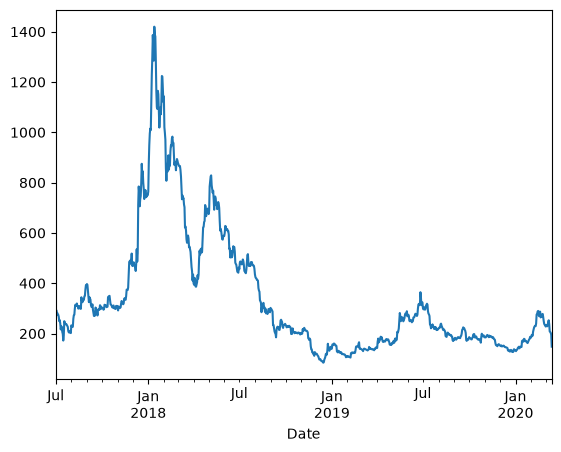

In [82]:
highs.plot()

In [83]:
# resampling on multiple columns
df1.drop(columns = 'Symbol', inplace=True)
df1.resample('D').mean()

TypeError: dtype 'str' does not support operation 'mean'

In [ ]:
df1.resample('W').mean()

,Open,High,Low,Close,Volume
Date,,,,,
2017-07-02,268.066486,271.124595,264.819730,268.202162,2.185035e+06
2017-07-09,261.337024,262.872917,259.186190,261.062083,1.337349e+06
2017-07-16,196.193214,199.204405,192.722321,195.698393,2.986756e+06
2017-07-23,212.351429,215.779286,209.126310,212.783750,4.298593e+06
2017-07-30,203.496190,205.110357,201.714048,203.309524,1.581729e+06
...,...,...,...,...,...
2020-02-16,255.021667,257.255238,252.679762,255.198452,2.329087e+06
2020-02-23,265.220833,267.263690,262.948512,265.321905,1.826094e+06
2020-03-01,236.720536,238.697500,234.208750,236.373988,2.198762e+06


In [ ]:
agg_data = df1.resample('W').agg({'Close':'mean', 'High':'max', 'Low':'min', 'Volume':'sum'})
agg_data

,Close,High,Low,Volume
Date,,,,
2017-07-02,268.202162,293.73,253.23,8.084631e+07
2017-07-09,261.062083,285.00,231.25,2.246746e+08
2017-07-16,195.698393,240.33,130.26,5.017750e+08
2017-07-23,212.783750,249.40,153.25,7.221637e+08
2017-07-30,203.309524,229.99,178.03,2.657305e+08
...,...,...,...,...
2020-02-16,255.198452,290.00,216.31,3.912867e+08
2020-02-23,265.321905,287.13,242.36,3.067838e+08
2020-03-01,236.373988,278.13,209.26,3.693920e+08


<Axes: title={'center': 'ETH daily high'}, xlabel='Date', ylabel='Price (USD)'>

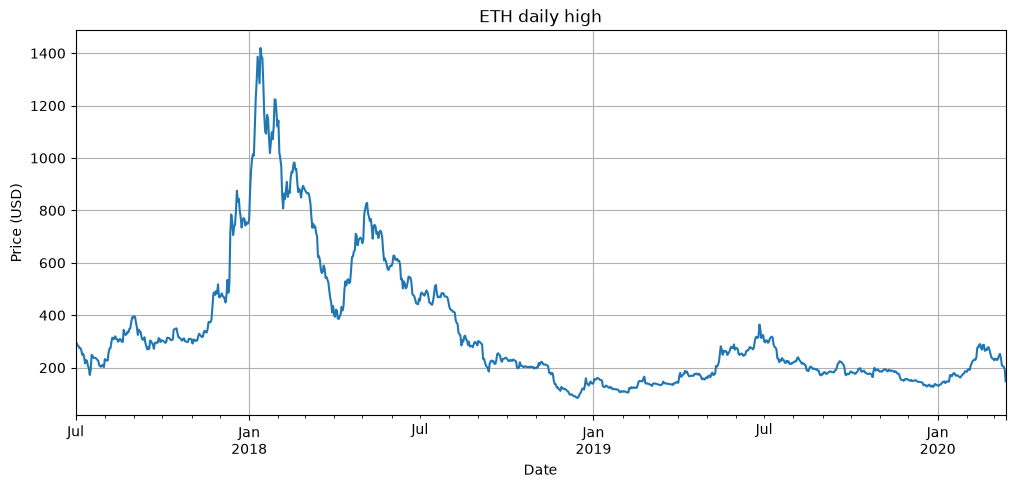

In [84]:
highs.plot(figsize=(12, 5), title='ETH daily high', ylabel='Price (USD)', grid=True)